# Vortices

Five whirlpools on a torus, turning alternately one way and the other, and 676 threads that
follow the flow around them, like a sky of galaxies. A slight drift turns closed orbits into
spirals: threads spiral out of the gold vortices and into the teal ones. Threads that leave one
edge come back in at the opposite edge, so the tile repeats seamlessly.

In [1]:
import math
import random

from common import mix, torus_segment
from nbturtle import render

W = H = 800
INK = "#0f1216"
TEAL = (0.19, 0.46, 0.50)
GOLD = (0.79, 0.64, 0.29)
IVORY = (0.90, 0.87, 0.81)
SEED = 6
VORTICES = 5
MIN_SEP = 150
EPS = 0.02
DRIFT = 0.15
SEEDS = 26
STEPS = 160
STEP = 2.5

## Placing the vortices

Random points at least `MIN_SEP` apart, measured on the torus: leaving one edge and coming back
in at the other counts, so two points near opposite edges are close.

In [2]:
def torus_dist(ax, ay, bx, by):
    dx, dy = abs(ax - bx), abs(ay - by)
    return math.hypot(min(dx, W - dx), min(dy, H - dy))


def make_vortices():
    out = []
    while len(out) < VORTICES:
        x, y = random.uniform(-W / 2, W / 2), random.uniform(-H / 2, H / 2)
        if all(torus_dist(x, y, vx, vy) >= MIN_SEP for vx, vy, _ in out):
            out.append((x, y, 1 if len(out) % 2 == 0 else -1))
    return out

## The flow

A stream function `psi` describes a flow that runs along its contour lines. Near a vortex,
`log(2 - cos(…) - cos(…))` behaves like the log of the squared distance, which is the stream
function of a single point vortex, and the cosines make it periodic. The velocity runs along the
contours, at right angles to the gradient of `psi`. `DRIFT` mixes in a little of the gradient
itself, and that turns circles into spirals. Only the direction is kept, so every thread moves at
the same speed.

In [3]:
def psi(vortices, x, y):
    s = 0
    for vx, vy, g in vortices:
        s -= g * math.log(2 - math.cos(2 * math.pi * (x - vx) / W)
                          - math.cos(2 * math.pi * (y - vy) / H) + EPS)
    return s


def velocity(vortices, x, y):
    e = 0.5
    gx = (psi(vortices, x + e, y) - psi(vortices, x - e, y)) / (2 * e)
    gy = (psi(vortices, x, y + e) - psi(vortices, x, y - e)) / (2 * e)
    vx, vy = gy - DRIFT * gx, -gx - DRIFT * gy
    n = math.hypot(vx, vy) or 1e-9
    return vx / n, vy / n

## Following a thread

Each thread starts at a jittered point of a grid and takes 160 steps of 2.5 px. Each step looks
at the velocity half a step ahead (the midpoint method), which stays on the curves far better
than a plain straight step. `torus_segment` splits a step that crosses an edge and continues it
from the opposite one. The color comes from `psi` where the thread starts: gold near vortices
turning one way, teal near the others.

Eight by eight threads, with the vortices marked:

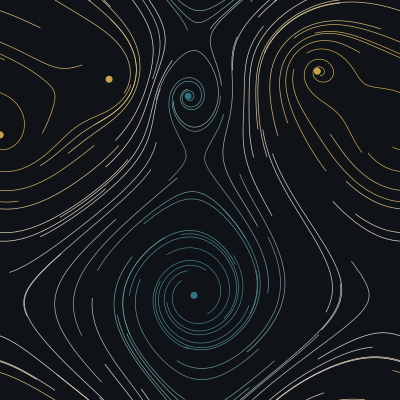

In [4]:
def shade(v):
    s = math.tanh(v / 2.5)
    return mix(IVORY, GOLD, s) if s > 0 else mix(IVORY, TEAL, -s)


def threads(t, vortices, seeds):
    t.pensize(1.4)
    for i in range(seeds):
        for j in range(seeds):
            x = -W / 2 + (i + random.random()) * W / seeds
            y = -H / 2 + (j + random.random()) * H / seeds
            t.pencolor(shade(psi(vortices, x, y)))
            t.goto(x, y)
            t.pendown()
            for _ in range(STEPS):
                ux, uy = velocity(vortices, x, y)
                ux, uy = velocity(vortices, x + 0.5 * STEP * ux, y + 0.5 * STEP * uy)
                x, y = torus_segment(t, (x, y), (x + STEP * ux, y + STEP * uy), W, H)
            t.penup()


def sketch(t):
    random.seed(SEED)
    vortices = make_vortices()
    threads(t, vortices, 8)
    for x, y, spin in vortices:
        t.goto(x, y)
        t.dot(14, GOLD if spin > 0 else TEAL)


render(sketch, W, H, INK, dpi=36)

## All 676 threads

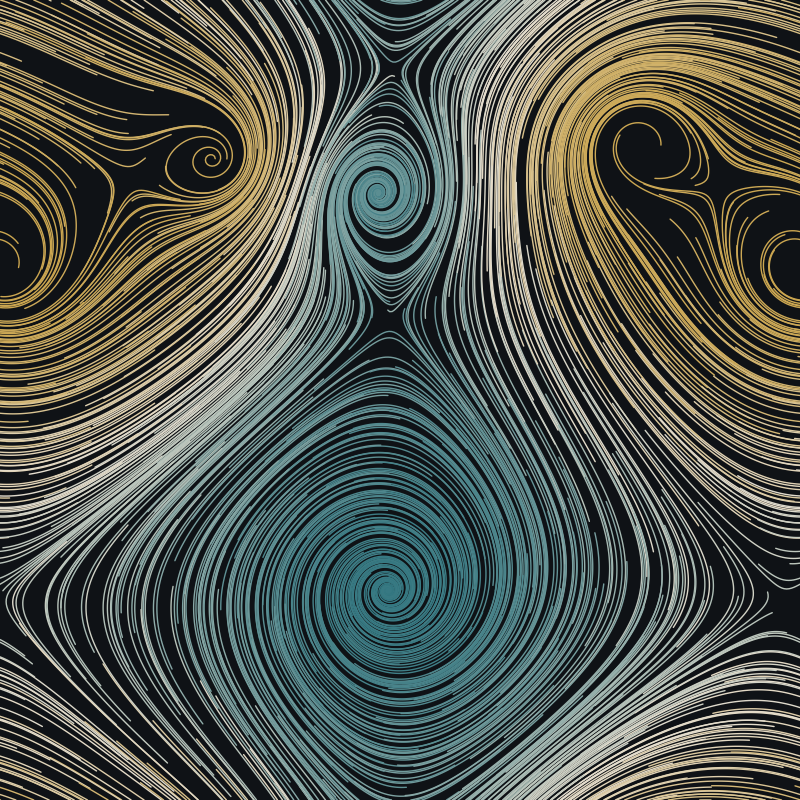

In [5]:
def draw(t):
    random.seed(SEED)
    threads(t, make_vortices(), SEEDS)


canvas = render(draw, W, H, INK)
canvas

## Does it repeat?

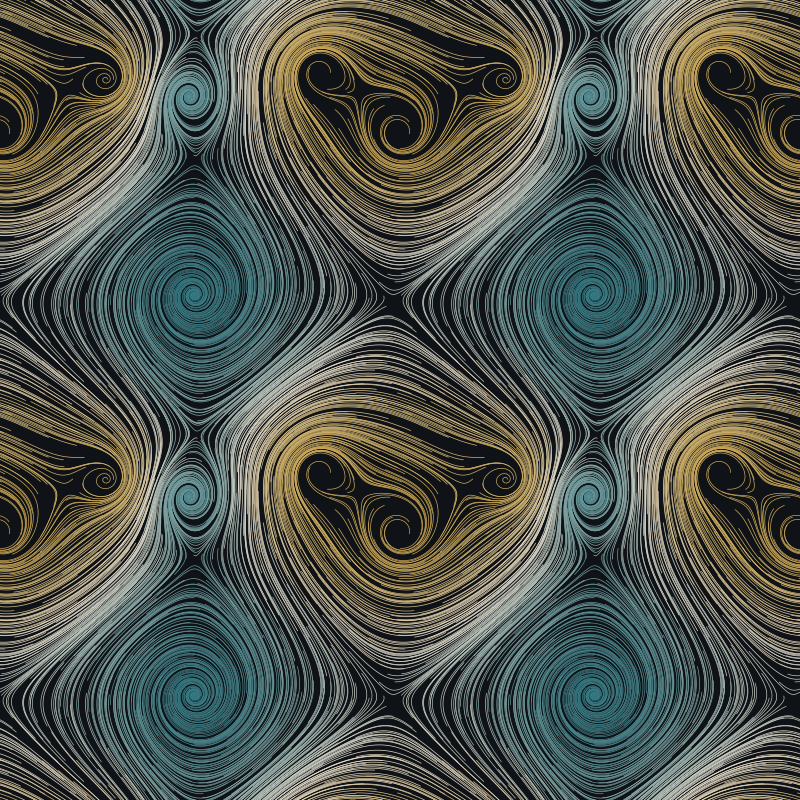

In [6]:
canvas.repeat()

## Try

- `DRIFT = 0` closes every spiral into an orbit; `DRIFT = 0.4` unwinds them fast.
- Another `SEED` moves the vortices; `VORTICES = 8` crowds the sky.
- `canvas.save("vortices.png", dpi=288)` writes a 3200 px tile, a 54 cm repeat when printed on
  fabric at 150 dpi.